In [2]:
import pickle
import pandas as pd
import numpy as np

with open("../data/model_data.pkl", "rb") as f:
    artifacts = pickle.load(f)

X_train = artifacts["X_train"]
X_val = artifacts["X_val"]
X_test = artifacts["X_test"]

y_train = artifacts["y_train"]
y_val = artifacts["y_val"]
y_test = artifacts["y_test"]

print("Artifacts loaded successfully!")

Artifacts loaded successfully!


In [3]:
for name, data in artifacts.items():
    if hasattr(data, "shape"):
        print(f"{name}: {data.shape}")

X_train: (54, 15)
X_val: (18, 15)
X_test: (19, 15)
y_train: (54,)
y_val: (18,)
y_test: (19,)


In [4]:
# Inspect training feature distributions

display(
    X_train.describe().T
)

,count,mean,std,min,25%,50%,75%,max
lag_1,54.0,691.175741,102.535472,472.000000,613.052500,660.380000,802.000000,849.000000
lag_2,54.0,692.603704,105.616034,472.000000,613.000000,660.380000,802.000000,849.000000
lag_3,54.0,695.050185,107.439967,472.000000,613.000000,660.380000,802.000000,849.000000
lag_4,54.0,698.994630,107.967747,472.000000,613.000000,660.380000,802.000000,849.000000
lag_5,54.0,703.226481,106.287084,472.000000,613.000000,690.555000,802.000000,849.000000
lag_6,54.0,705.155741,105.177758,472.000000,613.052500,707.775000,802.000000,849.000000
lag_7,54.0,705.347407,104.615511,472.000000,614.590000,708.000000,802.000000,849.000000
lag_8,54.0,707.147778,105.409415,472.000000,613.052500,708.000000,811.000000,849.000000
lag_9,54.0,708.796852,106.353320,472.000000,613.000000,708.000000,811.000000,849.000000
lag_10,54.0,710.919259,107.331866,472.000000,613.000000,710.000000,811.000000,849.000000


In [5]:
# Inspect extreme values

for column in X_train.select_dtypes(include="number").columns:
    print(f"\n{column}")
    print("Min:", X_train[column].min())
    print("Max:", X_train[column].max())
    print("Median:", X_train[column].median())


lag_1
Min: 472.0
Max: 849.0
Median: 660.38

lag_2
Min: 472.0
Max: 849.0
Median: 660.38

lag_3
Min: 472.0
Max: 849.0
Median: 660.38

lag_4
Min: 472.0
Max: 849.0
Median: 660.38

lag_5
Min: 472.0
Max: 849.0
Median: 690.555

lag_6
Min: 472.0
Max: 849.0
Median: 707.775

lag_7
Min: 472.0
Max: 849.0
Median: 708.0

lag_8
Min: 472.0
Max: 849.0
Median: 708.0

lag_9
Min: 472.0
Max: 849.0
Median: 708.0

lag_10
Min: 472.0
Max: 849.0
Median: 710.0

lag_11
Min: 472.0
Max: 849.0
Median: 726.5

lag_12
Min: 472.0
Max: 849.0
Median: 753.44

rolling_mean_3
Min: 495.3333333333333
Max: 841.0
Median: 660.38

rolling_mean_6
Min: 554.1666666666666
Max: 837.0
Median: 651.6741666666667

rolling_mean_12
Min: 599.4116666666666
Max: 825.0833333333334
Median: 704.4166666666667


In [6]:
print("TRAIN TARGET")
display(y_train.describe())

print("VALIDATION TARGET")
display(y_val.describe())

print("TEST TARGET")
display(y_test.describe())

TRAIN TARGET


count     54.000000
mean     690.655185
std       99.971402
min      472.000000
25%      614.982500
50%      663.190000
75%      801.972500
max      849.000000
Name: monthly_price, dtype: float64

VALIDATION TARGET


count      18.000000
mean     1382.330556
std       406.734822
min       910.000000
25%       975.500000
50%      1362.720000
75%      1652.520000
max      2193.000000
Name: monthly_price, dtype: float64

TEST TARGET


count      19.000000
mean     2250.613684
std       392.885250
min      1786.000000
25%      2005.000000
50%      2114.660000
75%      2436.000000
max      3086.000000
Name: monthly_price, dtype: float64

Your target distribution changes dramatically across the chronological split.<Br>

- The price regime changes substantially. The validation mean is approximately twice the training mean. The test mean is more than three times the training mean.
- This is not ordinary random fluctuation around a stable price level. The model is being evaluated across major changes in the underlying price level.
- Your lag features cannot directly show the future price regime. During training, the model sees prices no higher than 849, while validation targets reach 2,193.
- This explains an important limitation of the current models. Linear regression and Ridge can extrapolate, but they need a learnable relationship between the features and the rising price level. A Random Forest generally cannot extrapolate beyond the target values it learned.

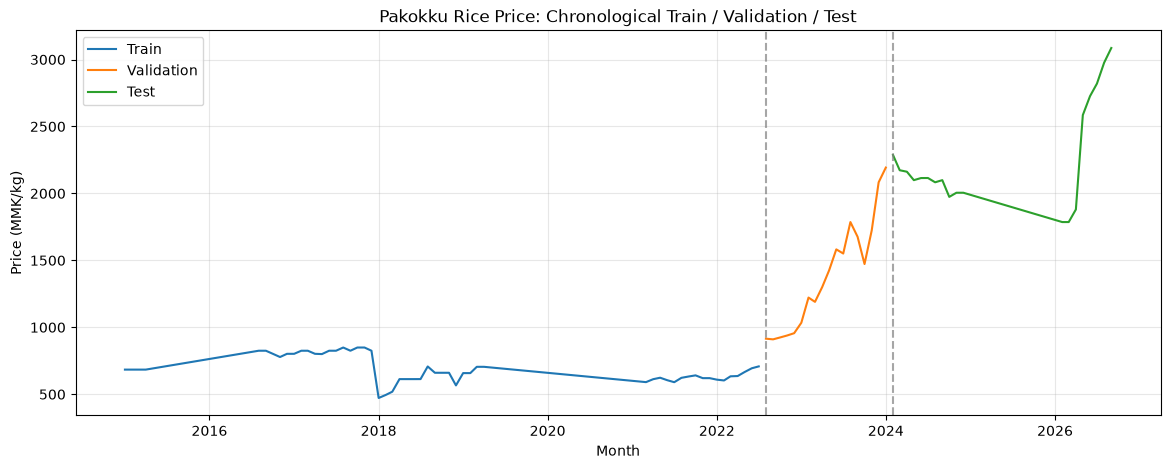

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(y_train.index.to_timestamp(), y_train, label="Train")
plt.plot(y_val.index.to_timestamp(), y_val, label="Validation")
plt.plot(y_test.index.to_timestamp(), y_test, label="Test")

plt.axvline(y_val.index[0].to_timestamp(), linestyle="--", color="gray", alpha=0.7)
plt.axvline(y_test.index[0].to_timestamp(), linestyle="--", color="gray", alpha=0.7)

plt.title("Pakokku Rice Price: Chronological Train / Validation / Test")
plt.xlabel("Month")
plt.ylabel("Price (MMK/kg)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()